# Wskaźnik ryzyka budynków i wrażliwość na `MAX_DISTANCE`

Notatnik rozwija analizę z `EGMS_buildings_analysis.ipynb` i odpowiada na dwa pytania:

1. **Które budynki są najbardziej narażone na skutki deformacji terenu?**
Dla każdego budynku z przypisanym punktem PS liczymy wskaźnik ryzyka łączący zachowanie punktu PS (prędkość osiadania, nietypowość) z cechami budynku (wysokość, typ).

2. **Jak wynik zależy od przyjętego progu `MAX_DISTANCE`?**
W notatniku `EGMS_buildings_analysis.ipynb` przyjęto 30 m. Sprawdzamy, jak zmienia się liczba budynków z przypisanym PS oraz lista budynków najwyższego ryzyka dla innych progów.

**Dane wejściowe:**

- `EGMS_Turow_U_results.csv` – punkty PS z wynikami Isolation Forest i K-means (`EGMS_analysis_pipeline.ipynb`),
- `budynki_Turow.gpkg` – obrysy budynków EUBUCCO (`EGMS_data_preparation.ipynb`).

**Wynik:** `budynki_ryzyko.gpkg` – budynki z przypisanym PS i wskaźnikiem ryzyka (do QGIS).

In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

# Wczytanie danych

Punkty PS i budynki przygotowujemy tak samo jak w `EGMS_buildings_analysis.ipynb`: usuwamy powtarzające się geometrie budynków, nadajemy im identyfikatory i sprowadzamy oba zbiory do układu EPSG:3035.

In [2]:
ps = pd.read_csv("EGMS_Turow_U_results.csv")

ps_gdf = gpd.GeoDataFrame(
    ps[["pid", "mean_velocity", "anomaly_score", "anomaly", "cluster"]],
    geometry=gpd.points_from_xy(ps["easting"], ps["northing"]),
    crs="EPSG:3035"
)

budynki = gpd.read_file("budynki_Turow.gpkg")
budynki = budynki.drop_duplicates(subset="geometry").reset_index(drop=True)
budynki["building_id"] = np.arange(1, len(budynki) + 1)
budynki = budynki.to_crs(ps_gdf.crs)

print("Liczba PS:", len(ps_gdf))
print("Liczba budynków:", len(budynki))

Liczba PS: 6268
Liczba budynków: 39156


## Przypisanie najbliższego PS

Funkcja `przypisz_ps()` powtarza metodę z `EGMS_buildings_analysis.ipynb`: każdy budynek dostaje najbliższy punkt PS, o ile leży on nie dalej niż `max_distance`. Gdy kilka punktów leży w tej samej odległości, wybieramy ten o najwyższym `anomaly_score`.

Funkcja przyda się w części 2, gdzie przypisanie powtarzamy dla różnych progów.

In [3]:
def przypisz_ps(max_distance):
    wynik = gpd.sjoin_nearest(
        budynki,
        ps_gdf,
        how="left",
        max_distance=max_distance,
        distance_col="distance_PS"
    )

    wynik = (
        wynik
        .sort_values(
            ["building_id", "distance_PS", "anomaly_score"],
            ascending=[True, True, False],
            na_position="last"
        )
        .drop_duplicates(subset="building_id", keep="first")
        .reset_index(drop=True)
    )

    return wynik

In [4]:
budynki_30 = przypisz_ps(30)

print("Budynki z PS do 30 m:", budynki_30["pid"].notna().sum())

Budynki z PS do 30 m: 15376


Liczba budynków z PS jest taka sama jak w `EGMS_buildings_analysis.ipynb`, więc przypisanie odtwarza wynik notatnika bazowego.

# CZĘŚĆ 1 — Wskaźnik ryzyka budynków

Korzystamy z klasycznej definicji ryzyka jako iloczynu **zagrożenia** i **podatności** (UNDRO, 1979):

`ryzyko = zagrożenie × podatność`

| Składnik | Cecha | Uzasadnienie |
|---|---|---|
| zagrożenie | `mean_velocity` (osiadanie) | szybsze osiadanie terenu → większe obciążenie konstrukcji |
| zagrożenie | `anomaly_score` | nietypowy przebieg deformacji (Isolation Forest) |
| podatność | `height` | wyższy budynek jest bardziej wrażliwy na przechylenie i nierównomierne osiadanie |
| podatność | `type` | w budynkach mieszkalnych stale przebywają ludzie |

Cechy mają różne jednostki, dlatego każdą zamieniamy na **rangę percentylową** (0–1) – jedną ze standardowych metod normalizacji przy budowie wskaźników złożonych (OECD/JRC, 2008): wartość 0,9 oznacza, że budynek ma wyższą wartość cechy niż 90% budynków. Dla prędkości bierzemy `-mean_velocity`, żeby najwyższą rangę miały budynki o najszybszym osiadaniu. Typ budynku kodujemy: mieszkalny = 1, niemieszkalny = 0,5.

Zagrożenie i podatność są średnimi swoich składników (równe wagi). Dzięki iloczynowi budynek na stabilnym terenie ma niskie ryzyko niezależnie od wysokości.

Wskaźnik jest **względny** – porządkuje budynki od najbardziej do najmniej narażonych w analizowanym obszarze, ale nie jest prawdopodobieństwem uszkodzenia.

In [5]:
def oblicz_ryzyko(df):
    # Tylko budynki z przypisanym PS
    df = df.dropna(subset=["pid"]).copy()

    # Zagrożenie – na podstawie punktu PS
    df["z_osiadanie"] = (-df["mean_velocity"]).rank(pct=True)
    df["z_anomalia"] = df["anomaly_score"].rank(pct=True)
    df["zagrozenie"] = (df["z_osiadanie"] + df["z_anomalia"]) / 2

    # Podatność – na podstawie cech budynku
    df["p_wysokosc"] = df["height"].rank(pct=True)
    df["p_typ"] = np.where(df["type"] == "residential", 1.0, 0.5)
    df["podatnosc"] = (df["p_wysokosc"] + df["p_typ"]) / 2

    df["ryzyko"] = df["zagrozenie"] * df["podatnosc"]

    return df

In [6]:
ryzyko_30 = oblicz_ryzyko(budynki_30)

print("Budynki ze wskaźnikiem ryzyka:", len(ryzyko_30))
ryzyko_30[["zagrozenie", "podatnosc", "ryzyko"]].describe().round(3)

Budynki ze wskaźnikiem ryzyka: 15376


,zagrozenie,podatnosc,ryzyko
count,15376.000,15376.000,15376.000
mean,0.500,0.628,0.314
std,0.237,0.236,0.198
min,0.076,0.250,0.022
25%,0.296,0.400,0.159
50%,0.474,0.633,0.267
75%,0.705,0.848,0.428
max,0.999,1.000,0.974


## Budynki najwyższego ryzyka

Analogicznie do progu anomalii w `EGMS_analysis_pipeline.ipynb` za budynki **najwyższego ryzyka** przyjmujemy umownie 5% budynków o najwyższym wskaźniku. Jest to próg wskazujący obiekty do dalszej obserwacji, a nie granica „bezpieczny / zagrożony”.

In [7]:
prog_ryzyka = ryzyko_30["ryzyko"].quantile(0.95)

ryzyko_30["wysokie_ryzyko"] = ryzyko_30["ryzyko"] >= prog_ryzyka

print("Próg ryzyka:", round(prog_ryzyka, 3))
print(ryzyko_30["wysokie_ryzyko"].value_counts())

Próg ryzyka: 0.718
wysokie_ryzyko
False    14607
True       769
Name: count, dtype: int64


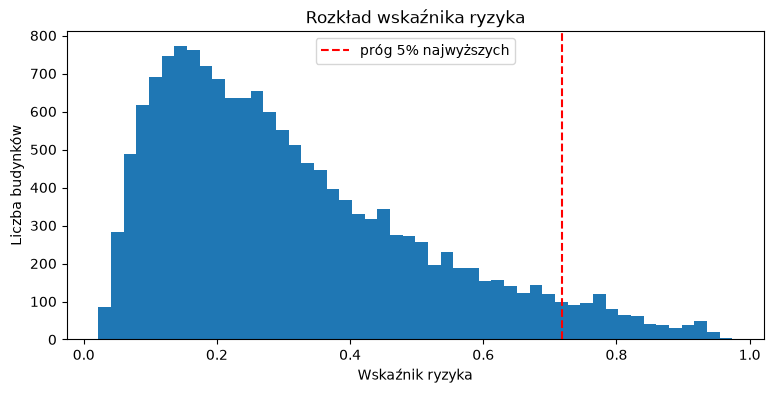

In [8]:
plt.figure(figsize=(9, 4))
plt.hist(ryzyko_30["ryzyko"], bins=50)
plt.axvline(prog_ryzyka, color="red", linestyle="--", label="próg 5% najwyższych")
plt.xlabel("Wskaźnik ryzyka")
plt.ylabel("Liczba budynków")
plt.title("Rozkład wskaźnika ryzyka")
plt.legend()
plt.show()

In [9]:
# 10 budynków o najwyższym wskaźniku ryzyka
ryzyko_30.nlargest(10, "ryzyko")[
    [
        "building_id",
        "kraj",
        "type",
        "height",
        "mean_velocity",
        "anomaly_score",
        "distance_PS",
        "zagrozenie",
        "podatnosc",
        "ryzyko"
    ]
].round(3)

,building_id,kraj,type,height,mean_velocity,anomaly_score,distance_PS,zagrozenie,podatnosc,ryzyko
9653,9654,DE,residential,19.1,-9.2,0.432,14.465,0.980,0.994,0.974
28401,28402,DE,residential,20.9,-8.0,0.419,0.000,0.968,0.997,0.966
37178,37179,DE,residential,19.0,-8.0,0.419,29.553,0.968,0.994,0.963
29907,29908,DE,residential,16.7,-8.4,0.424,27.045,0.974,0.984,0.958
21421,21422,DE,residential,18.1,-6.8,0.422,22.047,0.962,0.991,0.953
21422,21423,DE,residential,18.0,-6.8,0.422,22.292,0.962,0.991,0.953
21423,21424,DE,residential,18.0,-6.8,0.422,23.276,0.962,0.991,0.953
36974,36975,DE,residential,18.3,-7.7,0.410,0.000,0.956,0.992,0.949
17082,17083,DE,residential,17.4,-7.5,0.413,16.092,0.959,0.988,0.948
5227,5228,DE,residential,15.0,-8.4,0.424,5.698,0.974,0.971,0.946


## Ryzyko a kraj i typ budynku

Sprawdzamy, czy budynki najwyższego ryzyka koncentrują się w jednym kraju lub w jednym typie zabudowy.

In [10]:
ryzyko_kraj = ryzyko_30.groupby("kraj").agg(
    n_budynkow=("building_id", "count"),
    n_wysokie_ryzyko=("wysokie_ryzyko", "sum"),
    mediana_velocity=("mean_velocity", "median"),
    mediana_ryzyka=("ryzyko", "median")
)

ryzyko_kraj["procent_wysokie_ryzyko"] = (
    ryzyko_kraj["n_wysokie_ryzyko"]
    / ryzyko_kraj["n_budynkow"]
    * 100
)

ryzyko_kraj.round(2)

,n_budynkow,n_wysokie_ryzyko,mediana_velocity,mediana_ryzyka,procent_wysokie_ryzyko
kraj,,,,,
CZ,2762,26,-0.8,0.27,0.94
DE,9052,719,-1.2,0.29,7.94
PL,3562,24,-0.6,0.23,0.67


In [11]:
ryzyko_typ = ryzyko_30.groupby("type").agg(
    n_budynkow=("building_id", "count"),
    n_wysokie_ryzyko=("wysokie_ryzyko", "sum"),
    mediana_wysokosci=("height", "median"),
    mediana_ryzyka=("ryzyko", "median")
)

ryzyko_typ["procent_wysokie_ryzyko"] = (
    ryzyko_typ["n_wysokie_ryzyko"]
    / ryzyko_typ["n_budynkow"]
    * 100
)

ryzyko_typ.round(2)

,n_budynkow,n_wysokie_ryzyko,mediana_wysokosci,mediana_ryzyka,procent_wysokie_ryzyko
type,,,,,
non-residential,7490,0,3.6,0.19,0.00
residential,7886,769,7.8,0.37,9.75


## Mapa wskaźnika ryzyka

Budynki pokazujemy jako punkty (środki obrysów), bo w skali całego obszaru obrysy byłyby niewidoczne. Szare punkty to budynki bez PS w promieniu 30 m.

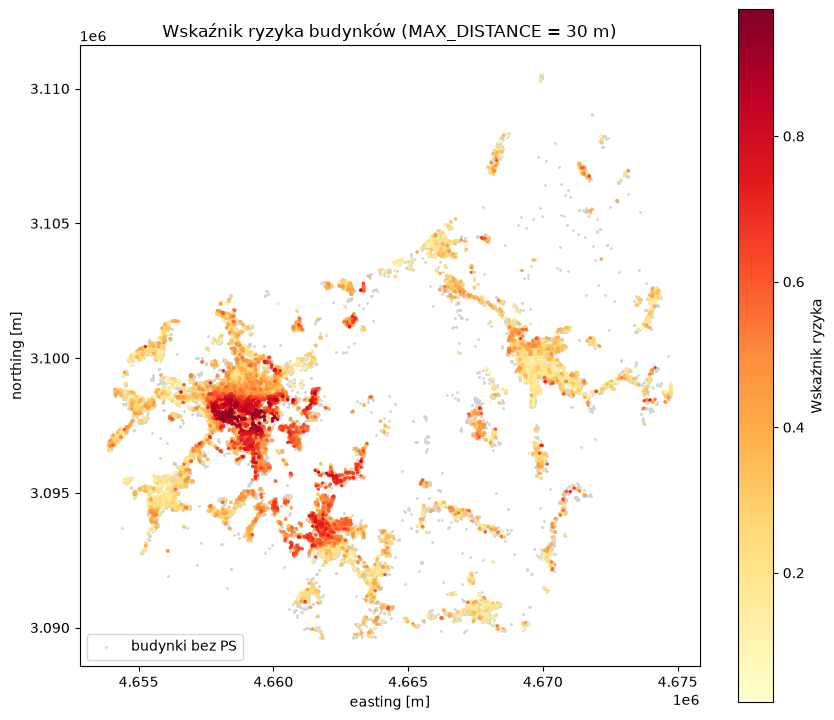

In [12]:
srodki_wszystkie = budynki.geometry.centroid

ryzyko_mapa = ryzyko_30.sort_values("ryzyko")
srodki_ryzyko = ryzyko_mapa.geometry.centroid

fig, ax = plt.subplots(figsize=(10, 9))

ax.scatter(srodki_wszystkie.x, srodki_wszystkie.y, s=1, color="lightgrey", label="budynki bez PS")

sc = ax.scatter(
    srodki_ryzyko.x,
    srodki_ryzyko.y,
    c=ryzyko_mapa["ryzyko"],
    s=2,
    cmap="YlOrRd"
)

plt.colorbar(sc, ax=ax, label="Wskaźnik ryzyka")
ax.set_aspect("equal")
ax.set_xlabel("easting [m]")
ax.set_ylabel("northing [m]")
ax.set_title("Wskaźnik ryzyka budynków (MAX_DISTANCE = 30 m)")
ax.legend(loc="lower left")
plt.show()

## Eksport do QGIS

In [13]:
export_cols = [
    "building_id",
    "id",
    "kraj",
    "type",
    "subtype",
    "height",
    "pid",
    "distance_PS",
    "mean_velocity",
    "anomaly_score",
    "cluster",
    "z_osiadanie",
    "z_anomalia",
    "zagrozenie",
    "p_wysokosc",
    "p_typ",
    "podatnosc",
    "ryzyko",
    "wysokie_ryzyko",
    "geometry"
]

ryzyko_30[export_cols].to_file(
    "budynki_ryzyko.gpkg",
    layer="budynki_ryzyko",
    driver="GPKG"
)

print("Zapisano: budynki_ryzyko.gpkg")

Zapisano: budynki_ryzyko.gpkg


# CZĘŚĆ 2 — Wrażliwość na `MAX_DISTANCE`

Powtarzamy przypisanie PS dla progów 10, 20, 30, 50, 70 i 100 m. Dla każdego progu sprawdzamy:

- ile budynków ma przypisany PS,
- ile różnych PS zostało wykorzystanych i ile budynków przypada średnio na jeden PS,
- medianę odległości budynek–PS oraz medianę prędkości przypisanych PS,
- jaka część listy budynków najwyższego ryzyka wyznaczonej przy 30 m pozostaje na liście przy innym progu,
- jaka część tej listy opiera się na PS odległym od budynku o więcej niż 30 m.

Przy innym progu zmienia się liczba budynków z PS, a więc i liczebność 5% najwyższych. Dlatego porównujemy listy **tej samej długości** – tyle budynków, ile przy 30 m ma wysokie ryzyko.

Ważna obserwacja: najbliższy PS budynku nie zależy od progu. Zwiększenie `MAX_DISTANCE` nie zmienia przypisania budynków, które miały PS już przy mniejszym progu – jedynie **dodaje** budynki położone dalej od punktów pomiarowych.

In [14]:
progi = [10, 20, 30, 50, 70, 100]

przypisania = {}
for d in progi:
    przypisania[d] = przypisz_ps(d)

# Długość porównywanych list – liczba budynków wysokiego ryzyka przy 30 m
n_top = ryzyko_30["wysokie_ryzyko"].sum()
top_30 = set(ryzyko_30.nlargest(n_top, "ryzyko")["building_id"])

wiersze = []
for d in progi:
    wynik_d = oblicz_ryzyko(przypisania[d])
    top_d = wynik_d.nlargest(n_top, "ryzyko")

    wiersze.append({
        "max_distance": d,
        "n_budynkow_z_PS": len(wynik_d),
        "procent_budynkow_z_PS": len(wynik_d) / len(budynki) * 100,
        "n_PS": wynik_d["pid"].nunique(),
        "budynki_na_PS": len(wynik_d) / wynik_d["pid"].nunique(),
        "mediana_odleglosci": wynik_d["distance_PS"].median(),
        "mediana_velocity": wynik_d["mean_velocity"].median(),
        "procent_wspolnych_top": len(top_30 & set(top_d["building_id"])) / n_top * 100,
        "procent_top_PS_ponad_30m": (top_d["distance_PS"] > 30).mean() * 100
    })

wrazliwosc = pd.DataFrame(wiersze)
wrazliwosc.round(2)

,max_distance,n_budynkow_z_PS,procent_budynkow_z_PS,n_PS,budynki_na_PS,mediana_odleglosci,mediana_velocity,procent_wspolnych_top,procent_top_PS_ponad_30m
0,10,3079,7.86,1832,1.68,5.19,-0.9,18.47,0.00
1,20,8092,20.67,2833,2.86,12.51,-0.9,52.67,0.00
2,30,15376,39.27,3450,4.46,19.39,-0.8,100.00,0.00
3,50,33536,85.65,4174,8.03,31.62,-0.8,47.72,52.28
4,70,38031,97.13,4300,8.84,34.05,-0.8,43.82,56.18
5,100,38553,98.46,4323,8.92,34.32,-0.8,43.56,56.44


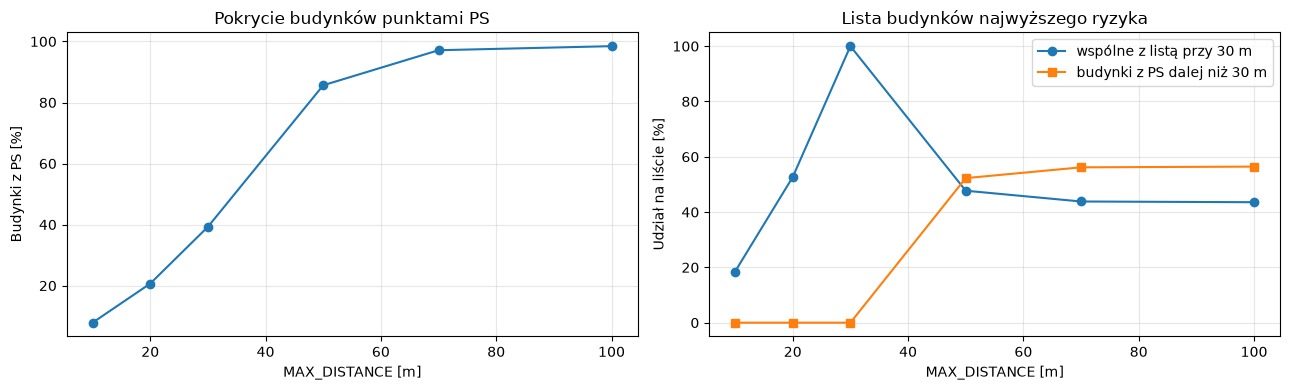

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(wrazliwosc["max_distance"], wrazliwosc["procent_budynkow_z_PS"], marker="o")
axes[0].set_xlabel("MAX_DISTANCE [m]")
axes[0].set_ylabel("Budynki z PS [%]")
axes[0].set_title("Pokrycie budynków punktami PS")
axes[0].grid(alpha=0.3)

axes[1].plot(wrazliwosc["max_distance"], wrazliwosc["procent_wspolnych_top"], marker="o", label="wspólne z listą przy 30 m")
axes[1].plot(wrazliwosc["max_distance"], wrazliwosc["procent_top_PS_ponad_30m"], marker="s", label="budynki z PS dalej niż 30 m")
axes[1].set_xlabel("MAX_DISTANCE [m]")
axes[1].set_ylabel("Udział na liście [%]")
axes[1].set_title("Lista budynków najwyższego ryzyka")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Pokrycie budynków w poszczególnych krajach

Sprawdzamy, czy próg wpływa jednakowo na budynki w Czechach, Polsce i Niemczech.

In [16]:
pokrycie_kraj = {}

for d in progi:
    wynik_d = przypisania[d]
    pokrycie_kraj[d] = wynik_d["pid"].notna().groupby(wynik_d["kraj"]).mean() * 100

pokrycie_kraj = pd.DataFrame(pokrycie_kraj)
pokrycie_kraj.columns.name = "MAX_DISTANCE [m]"

# Procent budynków z przypisanym PS
pokrycie_kraj.round(1)

MAX_DISTANCE [m],10,20,30,50,70,100
kraj,,,,,,
CZ,8.1,20.6,38.1,82.9,94.4,97.0
DE,7.8,20.3,39.2,86.7,98.2,99.3
PL,7.9,21.6,40.5,85.2,96.5,97.5


# Wnioski

## Wskaźnik ryzyka (`MAX_DISTANCE = 30 m`)

- Wskaźnik policzono dla 15 376 budynków (39%) – pozostałe nie mają punktu PS w promieniu 30 m.
- Grupę najwyższego ryzyka (5%, 769 budynków) tworzą wyłącznie budynki mieszkalne, w 93% położone w Niemczech (719 budynków, czyli 7,9% budynków z PS po stronie niemieckiej wobec 0,9% w Czechach i 0,7% w Polsce).
- Na mapie widać wyraźne skupisko budynków najwyższego ryzyka w Zittau i mniejsze w Hrádku nad Nisou. O wysokim wskaźniku decyduje przede wszystkim osiadanie przypisanych PS – dla dziesięciu budynków o najwyższym wskaźniku wynosi ono od 6,8 do 9,2 mm/rok.
- Budynki niemieszkalne nie znalazły się w grupie najwyższego ryzyka. Jest to bezpośredni skutek przyjętych założeń: niższej wagi typu (0,5) i mniejszej wysokości tych budynków (mediana 3,6 m wobec 7,8 m dla budynków mieszkalnych).

## Ograniczenia

- Wysokości budynków w EUBUCCO pochodzą z różnych źródeł (kolumna `h_src` w danych surowych): w Niemczech w 89% z danych urzędowych, w Polsce w 52%, a w Czechach 95% wysokości to wartości szacowane. Wysokości nie są więc w pełni porównywalne między krajami, co może zawyżać podatność budynków po stronie niemieckiej.
- Równe wagi składników i kodowanie typu budynku (1 / 0,5) są założeniami – inne wagi mogą zmienić kolejność budynków.
- Rangi percentylowe są względne: wskaźnik porządkuje budynki w analizowanym obszarze i nie jest porównywalny z innymi obszarami.
- Wskaźnik nie uwzględnia stanu technicznego, konstrukcji ani sposobu posadowienia budynków.

## Wrażliwość na `MAX_DISTANCE`

- Udział budynków z PS rośnie z 39% przy 30 m do 86% przy 50 m i 97% przy 70 m, a powyżej 70 m prawie się nie zmienia (98% przy 100 m). Wynika to z budowy danych EGMS L3: punkty są środkami komórek siatki 100 × 100 m, a żaden punkt komórki nie leży dalej niż ok. 71 m od jej środka.
- Jednocześnie jeden PS reprezentuje coraz więcej budynków (średnio 4,5 przy 30 m i 8,8 przy 70 m), a mediana odległości budynek–PS rośnie z 19 do 34 m.
- Lista budynków najwyższego ryzyka silnie zależy od progu. Przy 50 m tylko 48% budynków z listy wyznaczonej przy 30 m pozostaje na liście tej samej długości, a 52% listy to budynki, którym przypisano PS odległy o ponad 30 m. Przy progu 10 m na liście zostaje 18% budynków, a przy 20 m – 53%.
- Pokrycie zmienia się podobnie w Czechach, Polsce i Niemczech, więc wybór progu nie faworyzuje żadnego z krajów.
- **Rekomendacja:** 30 m jako wariant podstawowy – wskaźnik opiera się wtedy na punkcie z bezpośredniego sąsiedztwa budynku. Przy 50–70 m prawie wszystkie budynki mają PS, ale wynik należy traktować jako ocenę otoczenia budynku, a nie samego budynku.

## Literatura

- OECD/JRC (2008). *Handbook on Constructing Composite Indicators: Methodology and User Guide*. OECD Publishing, Paryż.
- UNDRO (1979). *Natural Disasters and Vulnerability Analysis*. Office of the United Nations Disaster Relief Co-ordinator, Genewa.
